In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [6]:
from langchain.chat_models import init_chat_model
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")

from langchain_groq import ChatGroq
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)


In [11]:
from langchain_tavily import TavilySearch

tavily_search_tool = TavilySearch(
    max_results=5,
    topic="general"
)
tavily_search_tool.invoke("what is the current AI news?")

{'query': 'what is the current AI news?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=TVRCcMlvR10',
   'title': 'AI News: 24 Things You Need To Know This Week',
   'content': "Here's the AI news you probably missed this week! Anthropic introduces Claude Duet, AI-powered cybersecurity threats are raising serious concerns, and OpenAI continues rolling out new updates. Plus, Ideogram's new vector model, ElevenLabs Chimera, and a rapid-fire roundup of the latest AI advancements.\n\nSharing the latest news and advancements in AI\n\nDiscover More:\n🛠️ Explore AI Tools & News: \n📰 Weekly Newsletter: [...] [23:10] brand new image model coming out of OpenAI. This week, Zoom introduced an AI tool to give enterprises greater visibility over AI activity. Basically,\n[23:19] it's for deep fake risk detection. So, if you're on a Zoom call, it will help you determine if you're actually talking to a human or being deep faked. I do

In [9]:
from langchain.tools import tool
@tool
def calculator(expression: str) -> str:
    """Calculate expression using Python's numexpr library."""

In [10]:
tool

<function langchain_core.tools.convert.tool(name_or_callable: str | collections.abc.Callable[..., Any] | None = None, runnable: langchain_core.runnables.base.Runnable[Any, Any] | None = None, *args: Any, description: str | None = None, return_direct: bool = False, args_schema: type[pydantic.main.BaseModel] | type[pydantic.v1.main.BaseModel] | dict[str, Any] | None = None, infer_schema: bool = True, response_format: Literal['content', 'content_and_artifact'] = 'content', parse_docstring: bool = False, error_on_invalid_docstring: bool = True, extras: dict[str, Any] | None = None) -> langchain_core.tools.base.BaseTool | collections.abc.Callable[[collections.abc.Callable[..., Any] | langchain_core.runnables.base.Runnable[Any, Any]], langchain_core.tools.base.BaseTool]>

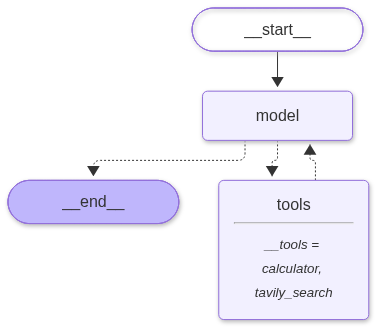

In [20]:
from langchain.agents import create_agent
agent = create_agent(
    model=model,
    tools=[calculator, tavily_search_tool]
)
agent

In [31]:
user_input = "What is the current AI news and calculate 2+2?"
for step in agent.stream(
    {"messages": user_input},
    stream_mode="values"
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

What is the current AI news and calculate 2+2?


================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_14fe0235-0871-448f-b48f-65d7dfb6d109)
 Call ID: fc_14fe0235-0871-448f-b48f-65d7dfb6d109
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=Z2Yw1f7TDrg", "title": "Top AI News 2 Nov 2026: OpenAI trims funding target", "content": "Google then released Gemini 4 Carbon, its most advanced, or frontier, model. It arrives two weeks after Gemini 4 Argon. Model prices are quoted per million tokens, and the list price is $4 per million tokens. On the security side, a modified, malicious build of Anthropic's Claude Code extension installed a hidden backdoor, a secret way in for attackers. Wi